<a href="https://colab.research.google.com/github/peter-adepoju/math-neuro-ml/blob/main/project/Project5_Starter.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **MAMBA Project Week — Option 5: Is Variability Shared Across Brain Areas?**

**Question.** When the mouse sees nothing, do neurons in different brain areas fluctuate together from trial to trial?

**Minimum result.** For the blank trials of session 11, the residual covariance matrix, the variance of the summed population against the sum of the individual variances, and the variance captured by the first principal component of the residuals.

**Lessons to revisit.** 3 (centring), 7 (covariance, PCA), 17 (variance of a sum), 20 (correlation, confounding).

**Data.** `steinmetz_s11_lederberg.npz` (and `steinmetz_s25_radnitz.npz` for the stretch goal). Steinmetz et al. (2019), *Nature* 576:266–273; subsets of the Neuromatch Academy release; the original data are released under CC0.

**How to use this notebook.** Run it top to bottom: it loads the data, shows it, and works one first step for you. Cells marked `# TODO` are yours; each is followed by a check cell that prints *TODO* until your code sets the variables it names, then tests their shapes and simple sanity conditions. Add your own cells freely, but keep every array described by its shape and units.

### Set-up

In [1]:
# SETUP -- run first.
import os, urllib.request
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(42)
PALETTE = ['#0072B2', '#D55E00', '#009E73', '#CC79A7', '#E69F00', '#56B4E9']   # Okabe-Ito, as in the lessons
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': False, 'figure.dpi': 100})
DATA_URL = 'https://raw.githubusercontent.com/peter-adepoju/math-neuro-ml/51d88220064023b5d3240c39e19b07acc7896f44/data/'

def load(name):
    # A local copy (here, or in the repository's data/ folder) first; otherwise download it from the pinned commit.
    for candidate in [name, os.path.join('..', 'data', name), os.path.join('..', '..', 'data', name)]:
        if os.path.exists(candidate):
            return np.load(candidate)
    urllib.request.urlretrieve(DATA_URL + name, name)
    return np.load(name)

def todo(*values):
    # True while any of the values is still None: the check cells below use it to wait for your code.
    return any(v is None for v in values)
print('Set-up complete.')

Set-up complete.


### Data tour

| Array | Shape | Meaning, units |
|---|---|---|
| `Xb` | (108, n_kept) | blank trials × neurons with a mean of at least 1 spike per 200 ms: spike counts |
| `Rb` | (108, n_kept) | residuals: each neuron's count minus its mean over blank trials |
| `area_k` | (n_kept,) | brain area of each kept neuron |
| `rt`, `trial_idx` | (108,) | response time (s) and position of the trial in the session |

Xb: (108, 162)  areas: {'CA1': 6, 'DG': 22, 'LGd': 3, 'LH': 7, 'MD': 62, 'PL': 1, 'SUB': 28, 'VISam': 19, 'VISp': 3, 'root': 11}


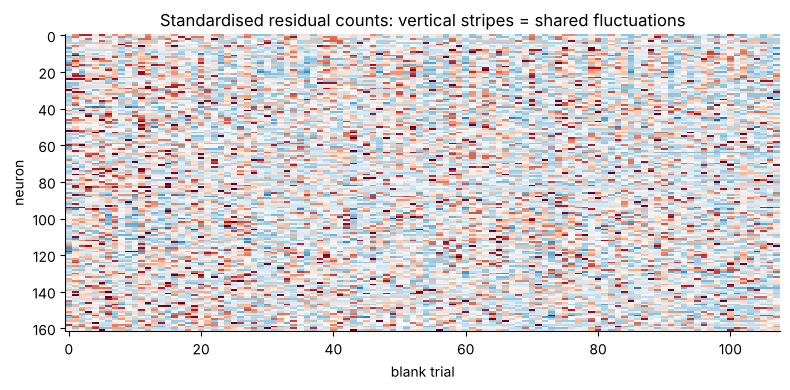

In [2]:
d = load('steinmetz_s11_lederberg.npz')
blank = (d['contrast_left'] == 0) & (d['contrast_right'] == 0)
X = d['counts'][blank].astype(float)                         # (108, 698) spikes per 200 ms
keep = X.mean(axis=0) >= 1
Xb, area_k = X[:, keep], d['brain_area'][keep]
Rb = Xb - Xb.mean(axis=0)                                    # (108, n_kept) residuals
rt, trial_idx = d['response_time_s'][blank], np.flatnonzero(blank)
print("Xb:", Xb.shape, " areas:", {str(a): int(n) for a, n in zip(*np.unique(area_k, return_counts=True))})
fig, ax = plt.subplots(figsize=(8, 4))
ax.imshow(Rb.T / Xb.std(axis=0)[:, None], aspect='auto', cmap='RdBu_r', vmin=-3, vmax=3, interpolation='nearest')
ax.set_xlabel('blank trial'); ax.set_ylabel('neuron'); ax.set_title('Standardised residual counts: vertical stripes = shared fluctuations')
plt.tight_layout(); plt.show()

### Worked first step: variance of a sum

In [3]:
pop = Xb.sum(axis=1)                                         # (108,) summed count
print(f"variance of the summed count {pop.var(ddof=1):.0f}; sum of individual variances {Xb.var(axis=0, ddof=1).sum():.0f};  "
      f"ratio {pop.var(ddof=1) / Xb.var(axis=0, ddof=1).sum():.1f} (1 if neurons were independent)")

variance of the summed count 4555; sum of individual variances 728;  ratio 6.3 (1 if neurons were independent)


In [4]:
# TODO 1 -- PCA of the standardised residuals (Lesson 7). Store evr (n_kept,): explained-variance ratios, largest first,
# and pc1 (n_kept,): the first principal axis (loadings). Plot a scree plot of the first 20.
evr = pc1 = None

In [5]:
if todo(evr, pc1):
    print('TODO 1 not done yet.')
else:
    assert abs(np.sum(evr) - 1) < 1e-8 and np.all(np.diff(evr) <= 1e-12)
    print('Check 1 passed.')

TODO 1 not done yet.


In [6]:
# TODO 2 -- Where does PC1 live, and what does it track? Store load_by_area = {area: mean loading of PC1 in that area}
# (fix the sign so that most loadings are positive), and the Pearson correlations of the PC1 score with response time
# (r_rt) and with trial position (r_trial).
load_by_area = r_rt = r_trial = None

In [7]:
if todo(load_by_area, r_rt, r_trial):
    print('TODO 2 not done yet.')
else:
    assert -1 <= r_rt <= 1 and -1 <= r_trial <= 1
    print('Check 2 passed.')

TODO 2 not done yet.


In [8]:
# TODO 3 -- Within versus between areas. From the correlation matrix of the residuals, store r_within (mean correlation of
# pairs in the same area, excluding the diagonal) and r_between (mean over pairs in different areas).
r_within = r_between = None

In [9]:
if todo(r_within, r_between):
    print('TODO 3 not done yet.')
else:
    assert -1 < r_between < 1 and -1 < r_within < 1
    print('Check 3 passed.')

TODO 3 not done yet.


### Before the talk
- Blank trials are spread over the session: slow drift creates shared variance. Check by removing a linear trend over trial position.
- With 108 trials and over 100 neurons, the covariance matrix is noisy: say how stable PC1 is (for example, split the trials in halves).
- Stretch: session 25 has only 40 blank trials; what does that do to the analysis?